> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/examples/mainline-and-feeders-explore.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Explore: A mainline and its feeders

How do two ship sizes on connected routes choose fuels when the ports supply them unevenly?

The case, its deck and its results are described on its [Examples page](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/examples/mainline-and-feeders.html).

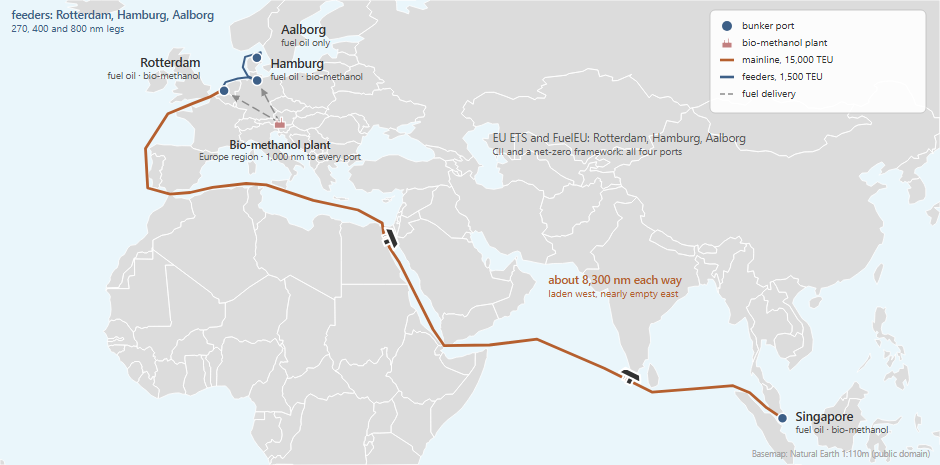

## STEP 1: Setup

Run the cell below on Colab or locally to set up Navigate and find the example deck.

In [ ]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, even when the `navigate`
# command itself is missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# The example deck.
EXAMPLE = Path("simulations/examples/example_1")
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there."
)


## STEP 2: Run the case

The cell below solves the case from 2026 to 2050 and draws its well-to-wake emissions, its freight rate and the fuel it burns.

In [ ]:
# @title Run the case and see the results
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# The workshop's figure and the functions that fill it, shared with the
# Examples pages: docs/workshop/_results.py.
sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _results import compare, plot_cases, print_summary, run_case, scale, summarise
from _solver import guard_interior_point

guard_interior_point()

NAV = Path("simulations/examples/example_1/example_1.nav")
%time ref = summarise(run_case(NAV))
print_summary(ref)
plot_cases({"reference": ref})
plt.show()


## STEP 3: Move one lever

Each number multiplies what the deck already says, so 1.0 is the reference. Set one, run the cell, and compare with the reference. As an example, the fuel oil price is doubled.

In [ ]:
# ===========================================================================
#  YOUR SCENARIO. Every number is a MULTIPLIER: 1.0 is the deck as it is.
# ===========================================================================
OIL_PRICE    = 2.0   # fuel oil price
EU_ETS_PRICE = 1.0   # EU ETS carbon price
BIOMASS_COST = 1.0   # cost of the biomass bio-methanol is made from

LEVERS = {
          "fossil_fuel_oil_price_global": OIL_PRICE,
          "eu_ets_carbon_credit_price": EU_ETS_PRICE,
          "feedstock_biomethanol_gasification_cost": BIOMASS_COST}
TWEAKS = [scale(f, v) for f, v in LEVERS.items() if v != 1.0]


def your_scenario(m):
    for t in TWEAKS:
        t(m)


compare(NAV, ref, your_scenario)
plt.show()


## Go further

- Edit the deck itself in `simulations/examples/example_1/` on a [local installation](https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/README.md#installation).
- See the other cases on the [Examples page](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/examples/index.html).